<a href="https://colab.research.google.com/github/naraganibhagyasree2007/CODETECH-Reinforcement-Learning-for-Game/blob/main/Reinforcement_Learning_for_Game.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# CODETECH Internship - Task 3
# Project: Reinforcement Learning for Games

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

print("Libraries imported successfully!")
print("Project setup completed.")

Libraries imported successfully!
Project setup completed.


In [2]:

# Step 2: Create the Treasure Hunt Game Environment

class TreasureHuntGame:

    def __init__(self):
        self.rows = 5
        self.cols = 5

        # Starting and goal positions
        self.start = (0, 0)
        self.goal = (4, 4)

        # Obstacle positions
        self.obstacles = [(1, 1), (2, 2), (3, 1)]

        # Four possible actions
        self.actions = {
            0: (-1, 0),  # Up
            1: (1, 0),   # Down
            2: (0, -1),  # Left
            3: (0, 1)    # Right
        }

        self.reset()

    # Reset the game
    def reset(self):
        self.agent_position = self.start
        return self.agent_position

    # Perform an action
    def step(self, action):

        row, col = self.agent_position
        dr, dc = self.actions[action]

        new_position = (row + dr, col + dc)

        # Default reward
        reward = -0.1
        done = False

        # Check game boundaries
        if (0 <= new_position[0] < self.rows and
            0 <= new_position[1] < self.cols):

            # Check obstacles
            if new_position in self.obstacles:
                reward = -5
            else:
                self.agent_position = new_position

        else:
            reward = -1

        # Check whether treasure is reached
        if self.agent_position == self.goal:
            reward = 10
            done = True

        return self.agent_position, reward, done

    # Display the game board
    def render(self):

        board = [["." for _ in range(self.cols)]
                 for _ in range(self.rows)]

        for obstacle in self.obstacles:
            r, c = obstacle
            board[r][c] = "X"

        gr, gc = self.goal
        board[gr][gc] = "G"

        ar, ac = self.agent_position
        board[ar][ac] = "S"

        print("\nTreasure Hunt Game")
        for row in board:
            print(" ".join(row))


# Create the game
game = TreasureHuntGame()

# Display the game
game.render()

print("\nGame environment created successfully!")
print("Starting Position:", game.agent_position)
print("Goal Position:", game.goal)
print("Available Actions: Up, Down, Left, Right")


Treasure Hunt Game
S . . . .
. X . . .
. . X . .
. X . . .
. . . . G

Game environment created successfully!
Starting Position: (0, 0)
Goal Position: (4, 4)
Available Actions: Up, Down, Left, Right


In [3]:

# Step 3: Initialize Q-Learning

# Create Q-table
q_table = np.zeros((5, 5, 4))

# Learning parameters
learning_rate = 0.1
discount_factor = 0.9
epsilon = 1.0

# Training parameters
episodes = 500
max_steps = 100
epsilon_decay = 0.995
min_epsilon = 0.01

print("Q-Learning initialized successfully!")
print("Q-Table Shape:", q_table.shape)
print("Episodes:", episodes)
print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)

Q-Learning initialized successfully!
Q-Table Shape: (5, 5, 4)
Episodes: 500
Learning Rate: 0.1
Discount Factor: 0.9


In [4]:

# Step 4: Train the Q-Learning Agent

rewards_history = []

for episode in range(episodes):

    state = game.reset()
    total_reward = 0

    for step in range(max_steps):

        row, col = state

        # Epsilon-greedy action selection
        if random.uniform(0, 1) < epsilon:
            action = random.randint(0, 3)
        else:
            action = np.argmax(q_table[row, col])

        # Perform action
        next_state, reward, done = game.step(action)

        nr, nc = next_state

        # Update Q-table
        old_value = q_table[row, col, action]
        next_max = np.max(q_table[nr, nc])

        new_value = old_value + learning_rate * (
            reward + discount_factor * next_max - old_value
        )

        q_table[row, col, action] = new_value

        state = next_state
        total_reward += reward

        if done:
            break

    rewards_history.append(total_reward)

    # Reduce exploration
    epsilon = max(min_epsilon, epsilon * epsilon_decay)

print("Training completed successfully!")
print("Total Episodes:", episodes)
print("Final Epsilon:", round(epsilon, 4))
print("Q-Table trained successfully!")

Training completed successfully!
Total Episodes: 500
Final Epsilon: 0.0816
Q-Table trained successfully!


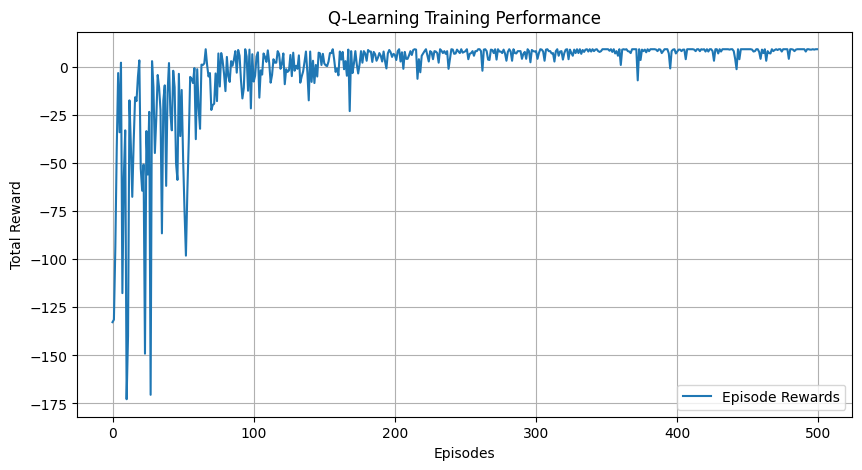

Training graph generated successfully!


In [5]:

# Step 5: Plot Training Rewards

plt.figure(figsize=(10, 5))

plt.plot(rewards_history, label="Episode Rewards")
plt.title("Q-Learning Training Performance")
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.legend()
plt.grid(True)

plt.savefig("training_performance.png", dpi=300)
plt.show()

print("Training graph generated successfully!")

In [6]:

# Step 6: Test the Trained Agent

state = game.reset()
total_reward = 0
done = False
test_steps = 0

print("AI Agent Testing Started\n")

game.render()

while not done and test_steps < 50:

    row, col = state

    # Select the best learned action
    action = np.argmax(q_table[row, col])

    next_state, reward, done = game.step(action)

    state = next_state
    total_reward += reward
    test_steps += 1

    print(f"Step {test_steps}: Position = {state}, Reward = {reward}")

    game.render()

print("\nTesting Completed!")
print("Total Steps:", test_steps)
print("Total Reward:", total_reward)
print("Goal Reached:", done)

AI Agent Testing Started


Treasure Hunt Game
S . . . .
. X . . .
. . X . .
. X . . .
. . . . G
Step 1: Position = (1, 0), Reward = -0.1

Treasure Hunt Game
. . . . .
S X . . .
. . X . .
. X . . .
. . . . G
Step 2: Position = (2, 0), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
S . X . .
. X . . .
. . . . G
Step 3: Position = (3, 0), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
S X . . .
. . . . G
Step 4: Position = (4, 0), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
. X . . .
S . . . G
Step 5: Position = (4, 1), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
. X . . .
. S . . G
Step 6: Position = (4, 2), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
. X . . .
. . S . G
Step 7: Position = (4, 3), Reward = -0.1

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
. X . . .
. . . S G
Step 8: Position = (4, 4), Reward = 10

Treasure Hunt Game
. . . . .
. X . . .
. . X . .
. X . . .
. . . . S

Testing Completed

In [7]:

# Step 7: Display the Learned Q-Table

print("Final Q-Table:\n")

for row in range(5):
    for col in range(5):
        print(
            f"State ({row}, {col}):",
            np.round(q_table[row, col], 2)
        )

print("\nQ-Table displayed successfully!")

Final Q-Table:

State (0, 0): [2.71 4.26 2.75 2.85]
State (0, 1): [-0.35 -3.97  3.61  1.35]
State (0, 2): [-0.68  0.48 -0.07  2.46]
State (0, 3): [0.72 1.85 0.59 3.76]
State (0, 4): [1.46 5.42 1.27 1.51]
State (1, 0): [ 3.66  4.85  3.26 -0.8 ]
State (1, 1): [0. 0. 0. 0.]
State (1, 2): [ 0.26 -4.56 -4.54  2.29]
State (1, 3): [0.35 3.29 0.66 5.02]
State (1, 4): [2.22 7.2  2.59 2.99]
State (2, 0): [4.13 5.5  3.93 4.06]
State (2, 1): [-2.64 -3.09  4.8  -2.87]
State (2, 2): [0. 0. 0. 0.]
State (2, 3): [ 2.21  3.68 -1.13  6.35]
State (2, 4): [2.48 8.71 3.33 5.21]
State (3, 0): [4.81 6.22 4.58 0.53]
State (3, 1): [0. 0. 0. 0.]
State (3, 2): [-0.49  7.9  -1.32  4.85]
State (3, 3): [3.4  8.83 3.93 7.15]
State (3, 4): [5.9  9.94 4.54 4.97]
State (4, 0): [5.44 5.28 5.3  7.02]
State (4, 1): [2.07 6.07 6.17 7.91]
State (4, 2): [6.97 6.99 6.87 8.9 ]
State (4, 3): [ 7.59  7.95  7.81 10.  ]
State (4, 4): [0. 0. 0. 0.]

Q-Table displayed successfully!


In [8]:

# Step 8: Save Training Results

results_df = pd.DataFrame({
    "Episode": range(1, episodes + 1),
    "Total_Reward": rewards_history
})

results_df.to_csv("training_results.csv", index=False)

np.save("q_table.npy", q_table)

print("Training results saved successfully!")
print("Files created:")
print("1. training_results.csv")
print("2. q_table.npy")
print("3. training_performance.png")

Training results saved successfully!
Files created:
1. training_results.csv
2. q_table.npy
3. training_performance.png


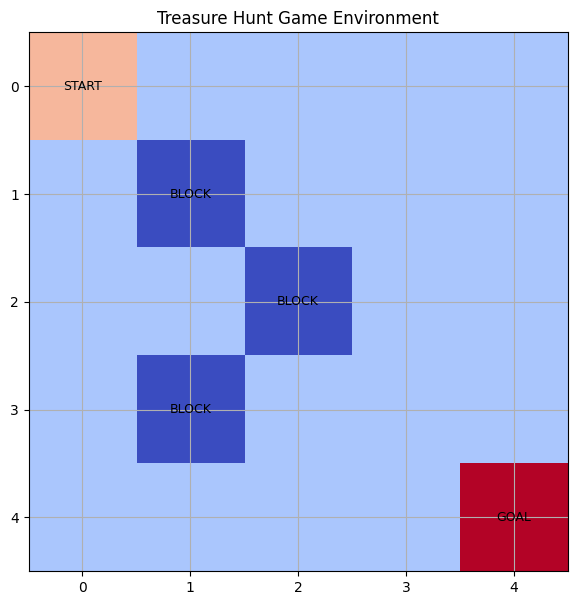

Game visualization saved successfully!


In [9]:

# Step 9: Create Game Environment Visualization

def visualize_game():
    board = np.zeros((5, 5))

    for obstacle in game.obstacles:
        board[obstacle] = -1

    board[game.goal] = 2
    board[game.start] = 1

    plt.figure(figsize=(7, 7))
    plt.imshow(board, cmap="coolwarm")

    for r in range(5):
        for c in range(5):
            if (r, c) == game.start:
                label = "START"
            elif (r, c) == game.goal:
                label = "GOAL"
            elif (r, c) in game.obstacles:
                label = "BLOCK"
            else:
                label = ""

            plt.text(c, r, label, ha="center", va="center",
                     fontsize=9)

    plt.title("Treasure Hunt Game Environment")
    plt.xticks(range(5))
    plt.yticks(range(5))
    plt.grid(True)
    plt.savefig("game_environment.png", dpi=300)
    plt.show()

    print("Game visualization saved successfully!")

visualize_game()

In [10]:

# Step 10: Final Project Summary

print("=" * 45)
print(" REINFORCEMENT LEARNING FOR GAMES")
print("=" * 45)

print("Project: Treasure Hunt Game")
print("Algorithm: Q-Learning")
print("Game Size: 5 x 5")
print("Training Episodes:", episodes)
print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)
print("Final Epsilon:", round(epsilon, 4))
print("Total Training Records:", len(rewards_history))

print("\nGenerated Project Files:")
print("1. training_results.csv")
print("2. q_table.npy")
print("3. training_performance.png")
print("4. game_environment.png")

print("\nPROJECT EXECUTION COMPLETED!")
print("=" * 45)

 REINFORCEMENT LEARNING FOR GAMES
Project: Treasure Hunt Game
Algorithm: Q-Learning
Game Size: 5 x 5
Training Episodes: 500
Learning Rate: 0.1
Discount Factor: 0.9
Final Epsilon: 0.0816
Total Training Records: 500

Generated Project Files:
1. training_results.csv
2. q_table.npy
3. training_performance.png
4. game_environment.png

PROJECT EXECUTION COMPLETED!


In [11]:

# Step 11: Create a ZIP file containing project outputs

import zipfile
import os

output_files = [
    "training_results.csv",
    "q_table.npy",
    "training_performance.png",
    "game_environment.png"
]

with zipfile.ZipFile("CODETECH_Task3_Outputs.zip", "w") as zipf:
    for file in output_files:
        if os.path.exists(file):
            zipf.write(file)

print("Project output ZIP created successfully!")
print("File: CODETECH_Task3_Outputs.zip")

from google.colab import files
files.download("CODETECH_Task3_Outputs.zip")

Project output ZIP created successfully!
File: CODETECH_Task3_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Step 12: Verify Project Files

import os

required_files = [
    "training_results.csv",
    "q_table.npy",
    "training_performance.png",
    "game_environment.png",
    "CODETECH_Task3_Outputs.zip"
]

print("PROJECT FILE VERIFICATION")
print("-" * 35)

for file in required_files:
    status = "FOUND" if os.path.exists(file) else "MISSING"
    print(f"{file}: {status}")

print("-" * 35)
print("Verification completed!")

PROJECT FILE VERIFICATION
-----------------------------------
training_results.csv: FOUND
q_table.npy: FOUND
training_performance.png: FOUND
game_environment.png: FOUND
CODETECH_Task3_Outputs.zip: FOUND
-----------------------------------
Verification completed!


In [13]:

# Step 13: Create Project README

readme_content = """
# CODETECH Internship - Task 3

## Project Name
Reinforcement Learning for Games

## Intern Details
- Full Name: Bhagya Sree Naragani
- Intern ID: [ADD YOUR INTERN ID]
- No. of Weeks: [ADD NUMBER OF WEEKS]

## Project Scope
Develop a game-playing AI agent using Reinforcement Learning
and Q-Learning.

## Project Overview
This project demonstrates how an AI agent learns to play
a Treasure Hunt game through rewards and penalties.

## Objectives
- Build a game environment.
- Implement Q-Learning.
- Train an AI agent.
- Test the trained agent.
- Visualize training performance.

## Technologies Used
- Python
- Google Colab
- NumPy
- Pandas
- Matplotlib

## Features
- 5x5 Treasure Hunt game.
- Four movement actions.
- Obstacles and rewards.
- Q-Learning algorithm.
- Training performance graph.
- Q-Table generation.

## Methodology
1. Create the game environment.
2. Initialize the Q-Table.
3. Train the agent.
4. Update Q-values.
5. Test the trained agent.
6. Visualize the results.

## How to Run
1. Open Google Colab.
2. Upload the project notebook.
3. Run the cells in order.
4. Observe the training results.

## Results
The agent learns a policy for navigating
the Treasure Hunt environment.

## Output Files
- training_results.csv
- q_table.npy
- training_performance.png
- game_environment.png

## Screenshots
Add project execution and visualization screenshots
inside the screenshots folder.

## Conclusion
This project demonstrates the application of
Reinforcement Learning using the Q-Learning algorithm.
"""

with open("README.md", "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [14]:

# Step 14: Display README Content

with open("README.md", "r") as file:
    print(file.read())


# CODETECH Internship - Task 3

## Project Name
Reinforcement Learning for Games

## Intern Details
- Full Name: Bhagya Sree Naragani
- Intern ID: [ADD YOUR INTERN ID]
- No. of Weeks: [ADD NUMBER OF WEEKS]

## Project Scope
Develop a game-playing AI agent using Reinforcement Learning
and Q-Learning.

## Project Overview
This project demonstrates how an AI agent learns to play
a Treasure Hunt game through rewards and penalties.

## Objectives
- Build a game environment.
- Implement Q-Learning.
- Train an AI agent.
- Test the trained agent.
- Visualize training performance.

## Technologies Used
- Python
- Google Colab
- NumPy
- Pandas
- Matplotlib

## Features
- 5x5 Treasure Hunt game.
- Four movement actions.
- Obstacles and rewards.
- Q-Learning algorithm.
- Training performance graph.
- Q-Table generation.

## Methodology
1. Create the game environment.
2. Initialize the Q-Table.
3. Train the agent.
4. Update Q-values.
5. Test the trained agent.
6. Visualize the results.

## How to 

In [15]:

# Step 15: Organize Project Screenshots

import os
import shutil

os.makedirs("screenshots", exist_ok=True)
os.makedirs("output", exist_ok=True)
os.makedirs("documentation", exist_ok=True)

# Copy generated images into screenshots
shutil.copy(
    "training_performance.png",
    "screenshots/training_performance.png"
)

shutil.copy(
    "game_environment.png",
    "screenshots/game_environment.png"
)

# Copy results into output
shutil.copy(
    "training_results.csv",
    "output/training_results.csv"
)

shutil.copy(
    "q_table.npy",
    "output/q_table.npy"
)

print("Project folders created successfully!")
print("Screenshots and output files organized!")

Project folders created successfully!
Screenshots and output files organized!


In [16]:

# Step 16: Package the Complete Project

import zipfile
import os

project_files = [
    "README.md",
    "screenshots/training_performance.png",
    "screenshots/game_environment.png",
    "output/training_results.csv",
    "output/q_table.npy"
]

with zipfile.ZipFile(
    "CODETECH_Task3_Final_Project.zip", "w"
) as zipf:

    for file in project_files:
        if os.path.exists(file):
            zipf.write(file)

print("Final project package created!")
print("CODETECH_Task3_Final_Project.zip")

from google.colab import files
files.download("CODETECH_Task3_Final_Project.zip")

Final project package created!
CODETECH_Task3_Final_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

# Step 17: Verify Complete Project Structure

import os

project_structure = [
    "README.md",
    "screenshots",
    "screenshots/training_performance.png",
    "screenshots/game_environment.png",
    "output",
    "output/training_results.csv",
    "output/q_table.npy",
    "documentation"
]

print("CODETECH TASK 3 - FINAL CHECK")
print("=" * 40)

for item in project_structure:
    if os.path.exists(item):
        print(f"[OK] {item}")
    else:
        print(f"[MISSING] {item}")

print("=" * 40)
print("Project structure verification completed!")

CODETECH TASK 3 - FINAL CHECK
[OK] README.md
[OK] screenshots
[OK] screenshots/training_performance.png
[OK] screenshots/game_environment.png
[OK] output
[OK] output/training_results.csv
[OK] output/q_table.npy
[OK] documentation
Project structure verification completed!


In [20]:

import os

print("Available files:")

for file in os.listdir("/content"):
    print(file)

Available files:
.config
CODETECH_Task3_Final_Project.zip
game_environment.png
screenshots
training_results.csv
CODETECH_Task3_Outputs.zip
README.md
documentation
q_table.npy
training_performance.png
output
sample_data


In [21]:

# Step 19: Create requirements.txt

requirements = """
numpy
pandas
matplotlib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

with open("requirements.txt", "r") as file:
    print("\nProject Dependencies:")
    print(file.read())

requirements.txt created successfully!

Project Dependencies:
numpy
pandas
matplotlib


In [22]:

# Step 20: Final Submission File Check

import os

required_files = [
    "README.md",
    "requirements.txt",
    "training_results.csv",
    "q_table.npy",
    "training_performance.png",
    "game_environment.png",
    "screenshots",
    "output",
    "documentation"
]

print("CODETECH TASK 3 SUBMISSION CHECK")
print("=" * 40)

for item in required_files:
    print(
        f"{'PASS' if os.path.exists(item) else 'MISSING'} : {item}"
    )

print("=" * 40)
print("Final file check completed!")

CODETECH TASK 3 SUBMISSION CHECK
PASS : README.md
PASS : requirements.txt
PASS : training_results.csv
PASS : q_table.npy
PASS : training_performance.png
PASS : game_environment.png
PASS : screenshots
PASS : output
PASS : documentation
Final file check completed!


In [25]:

# Step 21: Create GitHub-ready project folder

import os
import shutil

project_name = "CODETECH-Reinforcement-Learning-for-Games"

os.makedirs(project_name, exist_ok=True)

folders = ["screenshots", "output", "documentation"]

for folder in folders:
    os.makedirs(os.path.join(project_name, folder), exist_ok=True)

files_to_copy = [
    "README.md",
    "requirements.txt",
    "screenshots/training_performance.png",
    "screenshots/game_environment.png",
    "output/training_results.csv",
    "output/q_table.npy"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(file, os.path.join(project_name, file))

print("GitHub project folder created successfully!")
print("Repository:", project_name)

GitHub project folder created successfully!
Repository: CODETECH-Reinforcement-Learning-for-Games


In [26]:

import os
import zipfile
from google.colab import files

# Create project folder if it does not exist
project_name = "CODETECH-Reinforcement-Learning-for-Games"
os.makedirs(project_name, exist_ok=True)

# Create ZIP file
zip_name = project_name + ".zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, filenames in os.walk(project_name):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

print("GitHub ZIP created successfully!")
print("File:", zip_name)

# Download ZIP
files.download(zip_name)

GitHub ZIP created successfully!
File: CODETECH-Reinforcement-Learning-for-Games.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

import os

project_name = "CODETECH-Reinforcement-Learning-for-Games"

print("FINAL GITHUB REPOSITORY CHECK")
print("=" * 45)

for root, dirs, files_list in os.walk(project_name):
    for name in files_list:
        print("[FOUND]", os.path.join(root, name))

print("=" * 45)
print("Repository verification completed!")

FINAL GITHUB REPOSITORY CHECK
[FOUND] CODETECH-Reinforcement-Learning-for-Games/requirements.txt
[FOUND] CODETECH-Reinforcement-Learning-for-Games/README.md
[FOUND] CODETECH-Reinforcement-Learning-for-Games/screenshots/game_environment.png
[FOUND] CODETECH-Reinforcement-Learning-for-Games/screenshots/training_performance.png
[FOUND] CODETECH-Reinforcement-Learning-for-Games/output/training_results.csv
[FOUND] CODETECH-Reinforcement-Learning-for-Games/output/q_table.npy
Repository verification completed!


In [28]:

from google.colab import files

files.download(
    "CODETECH-Reinforcement-Learning-for-Games.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>